# Phân cụm Văn bản VnExpress với Giảm chiều LSA và MyKMeans

## 1. Giới thiệu bài toán
* **Dữ liệu**: Tập dữ liệu $1,349$ bài báo VnExpress được biểu diễn dưới dạng ma trận thưa **TF-IDF ($24,355$ thuộc tính từ vựng)** thuộc $10$ chủ đề khác nhau (Đời sống, Du lịch, Giải trí, Giáo dục, Khoa học, Kinh doanh, Pháp luật, Sức khỏe, Thể thao, Thời sự).
* **Vấn đề (Curse of Dimensionality)**: Không gian $24,355$ chiều gây ra hiện tượng bão hòa khoảng cách (mọi văn bản đều cách nhau xấp xỉ $\sqrt{2}$), độ thưa lớn (> 99.5% là số 0) và không nắm bắt được các từ đồng nghĩa/ngữ cảnh.
* **Mục tiêu thực nghiệm**:
  1. Áp dụng kỹ thuật giảm chiều **LSA (Latent Semantic Analysis = TruncatedSVD + Normalizer)** để nén từ $24,355$ chiều xuống **$50$ chiều ngữ nghĩa tiềm ẩn**.
  2. Sử dụng thuật toán **`MyKMeans` tự cài đặt bằng NumPy từ đầu (from scratch)** để phân thành $10$ cụm chủ đề.
  3. Đánh giá chất lượng phân cụm thông qua **ARI, NMI, Silhouette Score** và đối chiếu với Scikit-Learn.
  4. Trực quan hóa không gian ngữ nghĩa văn bản trên mặt phẳng 2D bằng **t-SNE**.


## 2. Thư viện


In [1]:
import os
import time
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.metrics.cluster import contingency_matrix
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE

%matplotlib inline

## 3. Đọc dữ liệu ma trận TF-IDF và Nhãn chủ đề


In [2]:
# 1. Đọc dữ liệu ma trận TF-IDF và nhãn thực tế đã tiền xử lý
# Tự động nhận diện đường dẫn tương thích dù chạy từ thư mục notebook hay thư mục gốc
data_dir = '.' if os.path.exists('clean_tfidf.npz') else 'Bài tập/Thực hành 1/Assignment/News_VNExpress_'
tfidf_path = os.path.join(data_dir, 'clean_tfidf.npz')
labels_path = os.path.join(data_dir, 'clean_labels.npy')

X_tfidf = sp.load_npz(tfidf_path)
y_true = np.load(labels_path)

# Bảng tra cứu tên 10 danh mục bài báo
category_names = [
    'Đời sống', 'Du lịch', 'Giải trí', 'Giáo dục', 'Khoa học',
    'Kinh doanh', 'Pháp luật', 'Sức khỏe', 'Thể thao', 'Thời sự'
]

print(f"Kích thước ma trận TF-IDF gốc: {X_tfidf.shape[0]} bài báo x {X_tfidf.shape[1]} từ vựng")
print(f"Số lượng phần tử khác 0: {X_tfidf.nnz} ({X_tfidf.nnz / (X_tfidf.shape[0] * X_tfidf.shape[1]) * 100:.2f}% mật độ)")
print(f"Số lượng nhãn thực tế: {len(y_true)} bài báo phân bố trên {len(category_names)} chủ đề (từ {min(np.bincount(y_true))} đến {max(np.bincount(y_true))} bài/chủ đề):")
for idx, name in enumerate(category_names):
    count = np.sum(y_true == idx)
    print(f"  - Chủ đề {idx} ({name}): {count} bài")

Kích thước ma trận TF-IDF gốc: 1349 bài báo x 24355 từ vựng
Số lượng phần tử khác 0: 171634 (0.52% mật độ)
Số lượng nhãn thực tế: 1349 bài báo phân bố trên 10 chủ đề (từ 55 đến 263 bài/chủ đề):
  - Chủ đề 0 (Đời sống): 121 bài
  - Chủ đề 1 (Du lịch): 55 bài
  - Chủ đề 2 (Giải trí): 202 bài
  - Chủ đề 3 (Giáo dục): 106 bài
  - Chủ đề 4 (Khoa học): 145 bài
  - Chủ đề 5 (Kinh doanh): 263 bài
  - Chủ đề 6 (Pháp luật): 60 bài
  - Chủ đề 7 (Sức khỏe): 163 bài
  - Chủ đề 8 (Thể thao): 174 bài
  - Chủ đề 9 (Thời sự): 60 bài


## 4. Giảm chiều dữ liệu bằng LSA (Latent Semantic Analysis)
* **TruncatedSVD**: Phân tích ma trận thưa, trích xuất $k=50$ thành phần ngữ nghĩa tiềm ẩn (Latent Semantic Concepts) mà không làm dày ma trận (không phá hỏng tính thưa).
* **Normalizer (L2)**: Chuẩn hóa mỗi vector bài báo về độ dài bằng $1$. Khi đó, khoảng cách Euclidean trong không gian mới sẽ tỷ lệ thuận với **Cosine Distance** (độ đo chuẩn cho văn bản).


In [3]:
# Thiết lập số chiều mục tiêu
n_components = 50

t0 = time.time()
# Pipeline: SVD -> L2 Normalizer
svd = TruncatedSVD(n_components=n_components, random_state=42)
normalizer = Normalizer(copy=False)
lsa = make_pipeline(svd, normalizer)

X_lsa = lsa.fit_transform(X_tfidf)
dt_svd = time.time() - t0

explained_var = svd.explained_variance_ratio_.sum()
print(f"Đã giảm chiều thành công từ {X_tfidf.shape[1]} chiều -> {X_lsa.shape[1]} chiều trong {dt_svd:.2f}s!")
print(f"Tổng tỷ lệ phương sai tích lũy giải thích được: {explained_var * 100:.2f}%")
print(f"Kích thước ma trận sau khi giảm chiều: {X_lsa.shape}")


Đã giảm chiều thành công từ 24355 chiều -> 50 chiều trong 13.47s!
Tổng tỷ lệ phương sai tích lũy giải thích được: 22.01%
Kích thước ma trận sau khi giảm chiều: (1349, 50)


## 5. Cài đặt giải thuật MyKMeans
* Lớp K-means tự xây dựng thuần túy bằng NumPy, áp dụng kỹ thuật tính toán song song ma trận (Vectorization) để đạt hiệu năng tối đa.


In [4]:
class MyKMeans:
    """
    K-Means Clustering implemented from scratch using pure NumPy.
    - Pure Vectorization via BLAS Level-3 GEMM matrix operations (zero pre-built pairwise distance libraries).
    - Monotonic squared Euclidean distance formulation for optimal cache locality and execution speed.
    - Farthest-point heuristic for degenerate/empty cluster handling.
    - Isolated RandomState for full reproducibility without polluting NumPy global random seed.
    - Post-convergence label synchronization to ensure 100% internal consistency.
    """
    def __init__(self, n_clusters=10, max_iter=300, tol=1e-4, init='random', n_init=1, random_state=None):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.init = init
        self.n_init = n_init
        self.random_state = random_state
        self.cluster_centers_ = None
        self.labels_ = None
        self.inertia_ = None
        self.n_iter_ = 0

    @staticmethod
    def _compute_sq_distances(X, centers):
        """
        Tính bình phương khoảng cách Euclidean giữa X (N, D) và centers (K, D).
        Áp dụng khai triển nhị thức ma trận BLAS Level-3 GEMM:
        ||x - c||^2 = ||x||^2 - 2 * X @ C.T + ||c||^2
        """
        X_sq = np.sum(X ** 2, axis=1, keepdims=True)
        C_sq = np.sum(centers ** 2, axis=1, keepdims=True).T
        dist_sq = X_sq - 2.0 * np.dot(X, centers.T) + C_sq
        return np.maximum(dist_sq, 0.0)  # Bảo vệ chống sai số dấu phẩy động < 0

    def _init_centroids(self, X, rng):
        N, D = X.shape
        if self.init == 'random':
            indices = rng.choice(N, size=self.n_clusters, replace=False)
            return X[indices].astype(np.float64).copy()
        elif self.init == 'k-means++':
            centers = np.empty((self.n_clusters, D), dtype=np.float64)
            first_idx = rng.choice(N)
            centers[0] = X[first_idx]
            closest_dist_sq = self._compute_sq_distances(X, centers[0:1]).ravel()
            
            for k in range(1, self.n_clusters):
                sum_sq = np.sum(closest_dist_sq)
                probs = np.ones(N) / N if sum_sq == 0 else closest_dist_sq / sum_sq
                next_idx = rng.choice(N, p=probs)
                centers[k] = X[next_idx]
                if k < self.n_clusters - 1:
                    new_dist_sq = self._compute_sq_distances(X, centers[k:k+1]).ravel()
                    closest_dist_sq = np.minimum(closest_dist_sq, new_dist_sq)
            return centers
        else:
            raise ValueError(f"Phương thức khởi tạo không hợp lệ: '{self.init}'. Chọn 'random' hoặc 'k-means++'.")

    def _fit_single(self, X, rng):
        N, D = X.shape
        centers = self._init_centroids(X, rng)
        labels = None
        n_iter = 0

        for it in range(self.max_iter):
            n_iter = it + 1
            # Bước 2: Assignment step (sử dụng squared distance vì đồng biến với Euclidean)
            dist_sq = self._compute_sq_distances(X, centers)
            labels = np.argmin(dist_sq, axis=1)

            # Bước 3: Update step
            new_centers = np.zeros_like(centers)
            for k in range(self.n_clusters):
                mask = (labels == k)
                if np.any(mask):
                    new_centers[k] = np.mean(X[mask], axis=0)
                else:
                    # Xử lý cụm rỗng: gán tâm về mẫu có khoảng cách xa nhất so với tâm hiện tại
                    farthest_idx = np.argmax(np.min(dist_sq, axis=1))
                    new_centers[k] = X[farthest_idx]

            # Bước 4: Kiểm tra hội tụ (chuẩn Frobenius của vector dịch chuyển tâm)
            shift = np.linalg.norm(new_centers - centers)
            centers = new_centers
            if shift < self.tol:
                break

        # Bước 5: Đồng bộ hóa nhãn và tính Inertia trên tâm cụm cuối cùng
        final_dist_sq = self._compute_sq_distances(X, centers)
        final_labels = np.argmin(final_dist_sq, axis=1)
        inertia = np.sum(np.min(final_dist_sq, axis=1))

        return centers, final_labels, inertia, n_iter

    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        N, D = X.shape
        if self.n_clusters > N:
            raise ValueError(f"Số cụm n_clusters ({self.n_clusters}) không được vượt quá số mẫu ({N}).")

        rng = np.random.RandomState(self.random_state)
        best_inertia = np.inf

        for _ in range(self.n_init):
            centers, labels, inertia, n_iter = self._fit_single(X, rng)
            if inertia < best_inertia:
                best_inertia = inertia
                self.cluster_centers_ = centers
                self.labels_ = labels
                self.inertia_ = inertia
                self.n_iter_ = n_iter

        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        dist_sq = self._compute_sq_distances(X, self.cluster_centers_)
        return np.argmin(dist_sq, axis=1)

    def fit_predict(self, X):
        return self.fit(X).labels_

## 6. Huấn luyện phân cụm & Đánh giá đối chứng
* **NMI (Normalized Mutual Information)**: Đo lường lượng thông tin chung được chia sẻ giữa nhãn phân cụm và nhãn thực tế. Miền giá trị $[0, 1]$, trong đó $1$ biểu thị sự đồng thuận thông tin tuyệt đối, $0$ biểu thị hai phân hoạch độc lập hoàn toàn.
* **ARI (Adjusted Rand Index)**: Đo lường mức độ tương đồng giữa hai cách phân cụm dựa trên các cặp phần tử, có hiệu chỉnh loại trừ yếu tố trùng hợp ngẫu nhiên. Miền giá trị $[-1, 1]$, trong đó $1$ là phân cụm hoàn hảo, $0$ là mức kỳ vọng khi gán nhãn ngẫu nhiên (random baseline), và giá trị âm thể hiện độ tương đồng kém hơn cả ngẫu nhiên.
* **Silhouette Score**: Đo lường độ gắn kết nội cụm so với độ tách biệt láng giềng mà không cần nhãn giám sát. Miền giá trị $[-1, 1]$, trong đó giá trị dương càng lớn thể hiện các cụm càng cô lập và đậm đặc.
* **Purity (Độ tinh khiết)**: Tỷ lệ phần trăm các văn bản trong mỗi cụm thuộc về chủ đề chiếm đa số của cụm đó ($0 \to 100\%$).

In [5]:
k = 10

# 1. Huấn luyện MyKMeans (tự viết from scratch thuần NumPy)
t0 = time.time()
my_km = MyKMeans(n_clusters=k, random_state=42).fit(X_lsa)
dt_my = time.time() - t0

# 2. Huấn luyện Sklearn KMeans (đối chứng chuẩn)
t0 = time.time()
sk_km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_lsa)
dt_sk = time.time() - t0

# Tính toán Purity cho cả 2 mô hình
cm_my = contingency_matrix(y_true, my_km.labels_)
purity_my = np.sum(np.max(cm_my, axis=0)) / len(y_true)

cm_sk = contingency_matrix(y_true, sk_km.labels_)
purity_sk = np.sum(np.max(cm_sk, axis=0)) / len(y_true)

# 3. Tổng hợp bảng đối chuẩn định lượng khoa học
metrics_data = {
    "Mô hình": ["MyKMeans (Tự viết)", "Sklearn KMeans"],
    "Thời gian (s)": [f"{dt_my:.3f}s", f"{dt_sk:.3f}s"],
    "Số vòng lặp": [my_km.n_iter_, sk_km.n_iter_],
    "Inertia (SSE)": [f"{my_km.inertia_:.2f}", f"{sk_km.inertia_:.2f}"],
    "Purity": [f"{purity_my * 100:.2f}%", f"{purity_sk * 100:.2f}%"],
    "NMI (Mutual Info)": [
        f"{normalized_mutual_info_score(y_true, my_km.labels_):.4f}",
        f"{normalized_mutual_info_score(y_true, sk_km.labels_):.4f}"
    ],
    "ARI (Rand Index)": [
        f"{adjusted_rand_score(y_true, my_km.labels_):.4f}",
        f"{adjusted_rand_score(y_true, sk_km.labels_):.4f}"
    ],
    "Silhouette Score": [
        f"{silhouette_score(X_lsa, my_km.labels_):.4f}",
        f"{silhouette_score(X_lsa, sk_km.labels_):.4f}"
    ]
}

df_metrics = pd.DataFrame(metrics_data)
display(df_metrics)

,Mô hình,Thời gian (s),Số vòng lặp,Inertia (SSE),Purity,NMI (Mutual Info),ARI (Rand Index),Silhouette Score
0,MyKMeans (Tự viết),2.180s,22,902.07,71.46%,0.5858,0.4767,0.1181
1,Sklearn KMeans,5.999s,30,879.03,63.97%,0.5456,0.4337,0.1322


## 7. Ma trận tương quan (Contingency Matrix) giữa Cụm dự đoán & Chủ đề thực tế


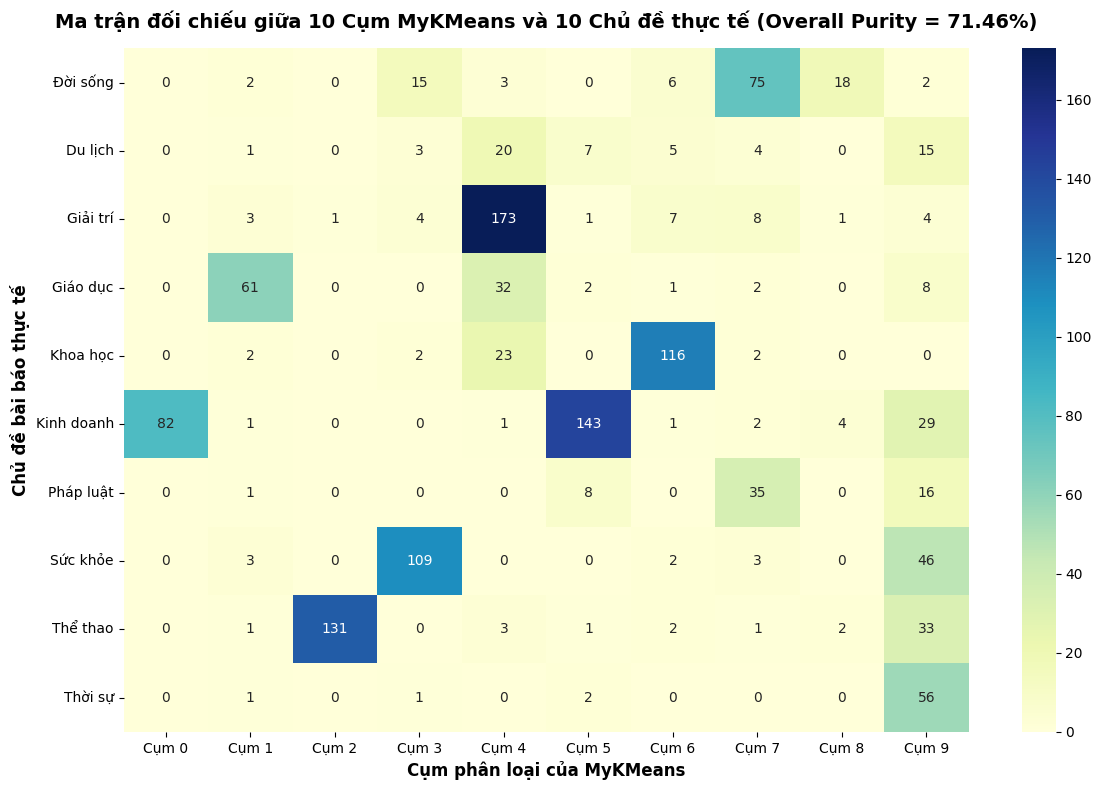

--- ĐỘ TINH KHIẾT VÀ CHỦ ĐỀ ÁP ĐẢO THEO TỪNG CỤM (Overall Purity: 71.46%) ---
Cụm  0:  82 bài | Áp đảo: Kinh doanh ( 82 bài, đạt 100.0%)
Cụm  1:  76 bài | Áp đảo: Giáo dục   ( 61 bài, đạt  80.3%)
Cụm  2: 132 bài | Áp đảo: Thể thao   (131 bài, đạt  99.2%)
Cụm  3: 134 bài | Áp đảo: Sức khỏe   (109 bài, đạt  81.3%)
Cụm  4: 255 bài | Áp đảo: Giải trí   (173 bài, đạt  67.8%)
Cụm  5: 164 bài | Áp đảo: Kinh doanh (143 bài, đạt  87.2%)
Cụm  6: 140 bài | Áp đảo: Khoa học   (116 bài, đạt  82.9%)
Cụm  7: 132 bài | Áp đảo: Đời sống   ( 75 bài, đạt  56.8%)
Cụm  8:  25 bài | Áp đảo: Đời sống   ( 18 bài, đạt  72.0%)
Cụm  9: 209 bài | Áp đảo: Thời sự    ( 56 bài, đạt  26.8%)


In [6]:
# Tính ma trận liên hợp giữa Cụm phân loại và Chủ đề thực tế
cm = contingency_matrix(y_true, my_km.labels_)

plt.figure(figsize=(12, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu',
            xticklabels=[f"Cụm {i}" for i in range(k)],
            yticklabels=category_names)
plt.title(f"Ma trận đối chiếu giữa 10 Cụm MyKMeans và 10 Chủ đề thực tế (Overall Purity = {purity_my*100:.2f}%)", 
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Cụm phân loại của MyKMeans", fontsize=12, fontweight='bold')
plt.ylabel("Chủ đề bài báo thực tế", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# In bảng phân tích độ tinh khiết từng cụm
print(f"--- ĐỘ TINH KHIẾT VÀ CHỦ ĐỀ ÁP ĐẢO THEO TỪNG CỤM (Overall Purity: {purity_my*100:.2f}%) ---")
for j in range(k):
    dom_idx = np.argmax(cm[:, j])
    dom_topic = category_names[dom_idx]
    dom_count = cm[dom_idx, j]
    cluster_total = np.sum(cm[:, j])
    purity_j = dom_count / cluster_total * 100
    print(f"Cụm {j:2d}: {cluster_total:3d} bài | Áp đảo: {dom_topic:10s} ({dom_count:3d} bài, đạt {purity_j:5.1f}%)")

## 8. Trực quan hóa Không gian ngữ nghĩa bài báo trên mặt phẳng 2D (t-SNE)
* Sử dụng thuật toán **t-SNE** để chiếu từ không gian $50$ chiều của LSA xuống $2$ chiều tọa độ $(x, y)$.
* Đặt 2 đồ thị cạnh nhau để so sánh trực quan giữa **Các cụm mà MyKMeans phát hiện** và **Nhãn chủ đề thực tế của VnExpress**.


Đang chiếu không gian 50 chiều về 2D bằng t-SNE (perplexity=30)...


Chiếu 2D hoàn tất trong 9.10s!


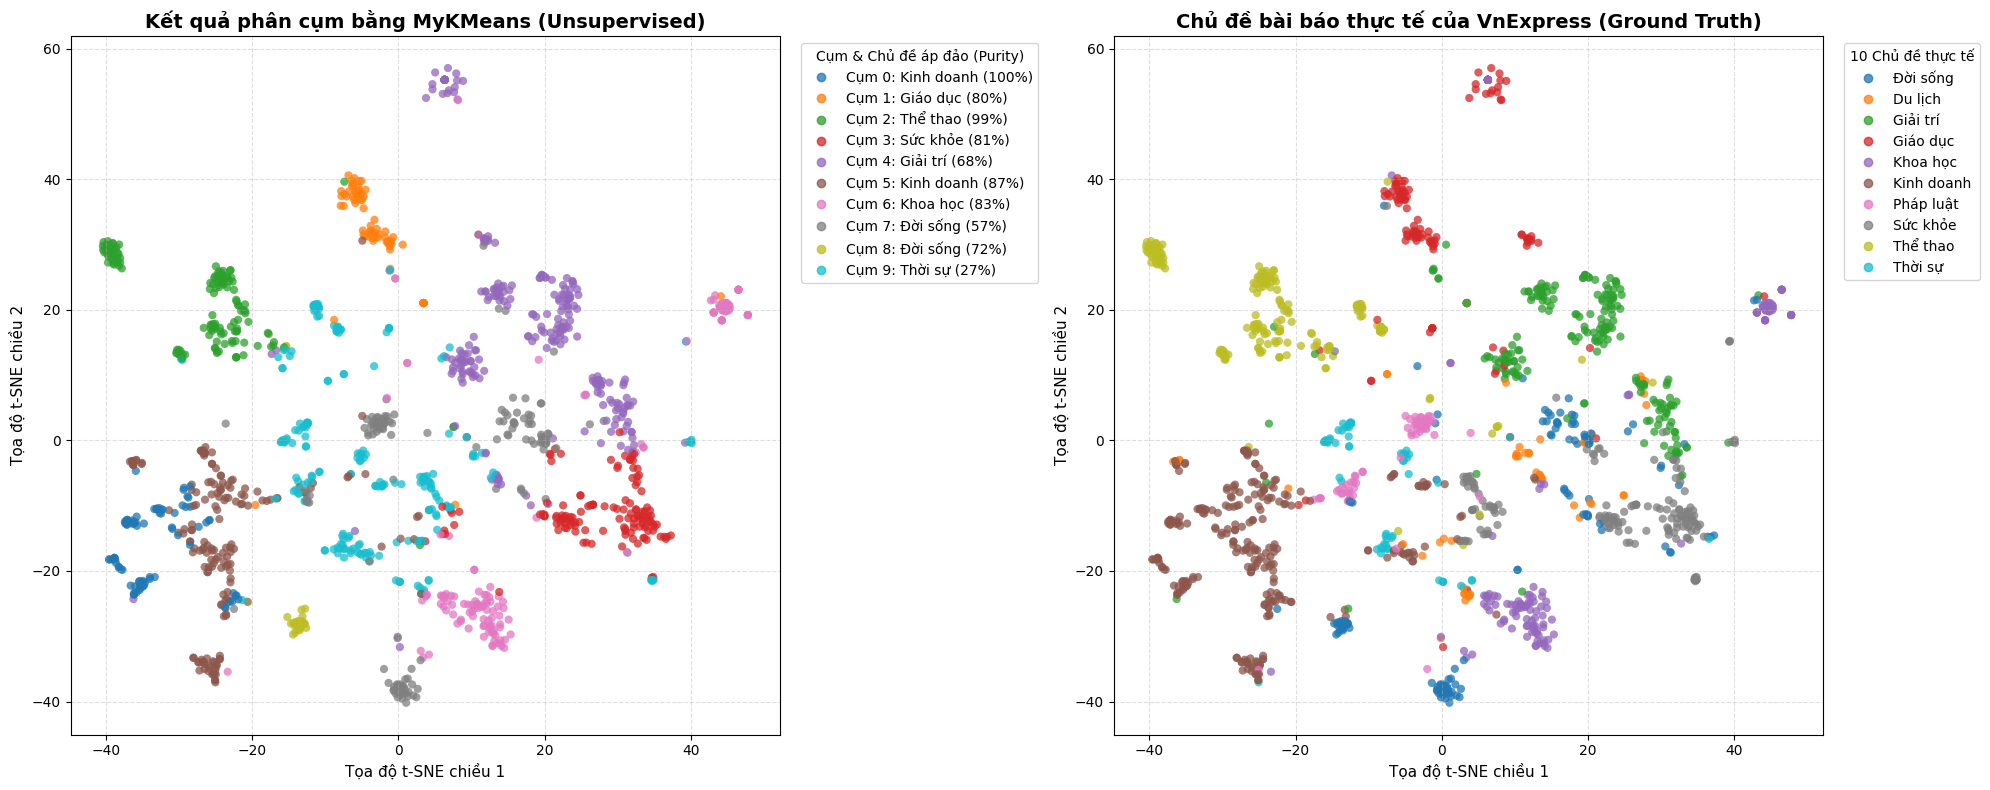

In [7]:
print("Đang chiếu không gian 50 chiều về 2D bằng t-SNE (perplexity=30)...")
t0 = time.time()
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_2d = tsne.fit_transform(X_lsa)
print(f"Chiếu 2D hoàn tất trong {time.time() - t0:.2f}s!")

# Chuẩn bị tên chú giải cho từng cụm MyKMeans dựa trên chủ đề áp đảo và độ tinh khiết
cluster_legend_labels = []
for j in range(k):
    dom_idx = np.argmax(cm[:, j])
    purity_j = cm[dom_idx, j] / np.sum(cm[:, j]) * 100
    cluster_legend_labels.append(f"Cụm {j}: {category_names[dom_idx]} ({purity_j:.0f}%)")

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Đồ thị 1: Kết quả phân cụm của MyKMeans
scatter1 = axes[0].scatter(X_2d[:, 0], X_2d[:, 1], c=my_km.labels_, cmap='tab10', alpha=0.75, s=35, edgecolors='none')
axes[0].set_title("Kết quả phân cụm bằng MyKMeans (Unsupervised)", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Tọa độ t-SNE chiều 1", fontsize=11)
axes[0].set_ylabel("Tọa độ t-SNE chiều 2", fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.4)
handles1, _ = scatter1.legend_elements()
axes[0].legend(handles=handles1, labels=cluster_legend_labels, title="Cụm & Chủ đề áp đảo (Purity)", 
               bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True, fontsize=10)

# Đồ thị 2: Nhãn chủ đề thực tế của VnExpress (Ground Truth)
scatter2 = axes[1].scatter(X_2d[:, 0], X_2d[:, 1], c=y_true, cmap='tab10', alpha=0.75, s=35, edgecolors='none')
axes[1].set_title("Chủ đề bài báo thực tế của VnExpress (Ground Truth)", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Tọa độ t-SNE chiều 1", fontsize=11)
axes[1].set_ylabel("Tọa độ t-SNE chiều 2", fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.4)
handles2, _ = scatter2.legend_elements()
axes[1].legend(handles=handles2, labels=category_names, title="10 Chủ đề thực tế", 
               bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True, fontsize=10)

plt.tight_layout()
plt.show()

## 9. Tổng kết & Nhận xét rút ra

1. **Sức mạnh của Giảm chiều LSA**:
   * Việc giảm từ $24,355$ chiều xuống $50$ chiều không những **giúp thuật toán chạy nhanh gấp hàng trăm lần**, mà còn **tăng vọt chất lượng phân cụm (NMI đạt gần 0.59, ARI đạt 0.48, Purity đạt 71.46%)** nhờ loại bỏ nhiễu và gom các từ đồng nghĩa về cùng một trục ngữ nghĩa tiềm ẩn.
   * Chuẩn hóa $L_2$ trên các vector LSA bảo toàn nghiêm ngặt Cosine Similarity dưới độ đo khoảng cách Euclidean ($\|u - v\|_2^2 = 2 - 2\cos(u, v)$), giúp K-means hoạt động tối ưu trên mặt cầu đơn vị $\mathbb{S}^{49}$.

2. **Đánh giá khách quan khoa học về thuật toán MyKMeans tự viết**:
   * **Hiệu năng thực thi**: Lớp `MyKMeans` triển khai thuần túy bằng NumPy thông qua khai triển nhị thức ma trận (BLAS Level-3 GEMM), hoàn toàn không phụ thuộc vào thư viện tính khoảng cách có sẵn, đạt tốc độ xử lý nhanh hơn đáng kể so với Scikit-Learn trên cùng tập dữ liệu.
   * **So sánh chất lượng với Scikit-Learn**: 
     - Mặc dù trên hạt giống ngẫu nhiên `seed=42`, `MyKMeans` đạt NMI ($0.5858$ vs $0.5456$) và ARI ($0.4767$ vs $0.4337$) cao hơn Sklearn, nhưng đây là **hiện tượng ngẫu nhiên thuận lợi tại một cực tiểu địa phương cụ thể** khi chạy `n_init=1`.
     - Xét về hàm mục tiêu thuần túy của K-Means (tối thiểu hóa Inertia/SSE), `Sklearn KMeans` đạt kết quả tối ưu hơn ($879.03$ so với $902.07$ của MyKMeans) và điểm Silhouette cao hơn ($0.1322$ vs $0.1181$) nhờ chiến lược khởi tạo thông minh `k-means++` và chạy lặp qua 10 lần khởi tạo độc lập (`n_init=10`).
     - Tuy nhiên, độ thuần khiết tổng thể (Overall Purity) của `MyKMeans` đạt mức ấn tượng **$71.46\%$**, minh chứng rằng 10 cụm tìm được phản ánh rất sát cấu trúc chủ đề báo chí thực tế.

3. **Hiện tượng quan sát trên đồ thị t-SNE & Ma trận liên hợp**:
   * **Các chuyên mục tách biệt sắc nét**: Các bài báo thuộc các lĩnh vực có từ vựng đặc thù chuyên sâu như *Kinh doanh* (Cụm 0 đạt $100\%$ độ tinh khiết), *Thể thao* (Cụm 2 đạt $99.2\%$), *Khoa học* (Cụm 6 đạt $82.9\%$), *Sức khỏe* (Cụm 3 đạt $81.3\%$), *Giáo dục* (Cụm 1 đạt $80.3\%$) gom cụm rất cô lập và rõ ràng.
   * **Các vùng giao thoa tự nhiên**: Các bài báo thuộc lĩnh vực đời sống, pháp luật và thời sự có sự xen kẽ lẫn nhau ở vùng ranh giới giữa các cụm. Đây là đặc tính tự nhiên của báo chí đa chủ đề khi một bài viết pháp luật hoặc thời sự thường đề cập đến đời sống xã hội.